In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('../data/raw/creditcard.csv')

In [4]:
print(df.shape)

(284807, 31)


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
print(df['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [7]:

duplicates = df[df.duplicated()]
print(duplicates['Class'].value_counts())

Class
0    1062
1      19
Name: count, dtype: int64


In [8]:
print(df[['Time','Amount']].describe())

                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


In [9]:
print(df.groupby('Class')['Amount'].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

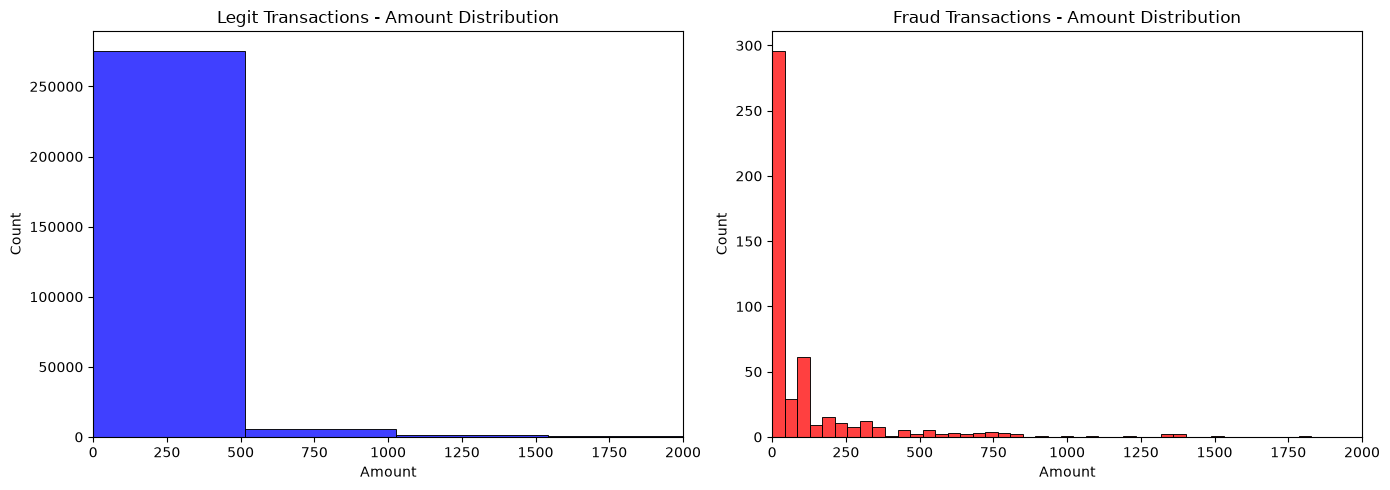

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[df['Class']==0]['Amount'], bins=50, ax=axes[0], color='blue')
axes[0].set_title('Legit Transactions - Amount Distribution')
axes[0].set_xlim(0, 2000)

sns.histplot(df[df['Class']==1]['Amount'], bins=50, ax=axes[1], color='red')
axes[1].set_title('Fraud Transactions - Amount Distribution')
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.show()

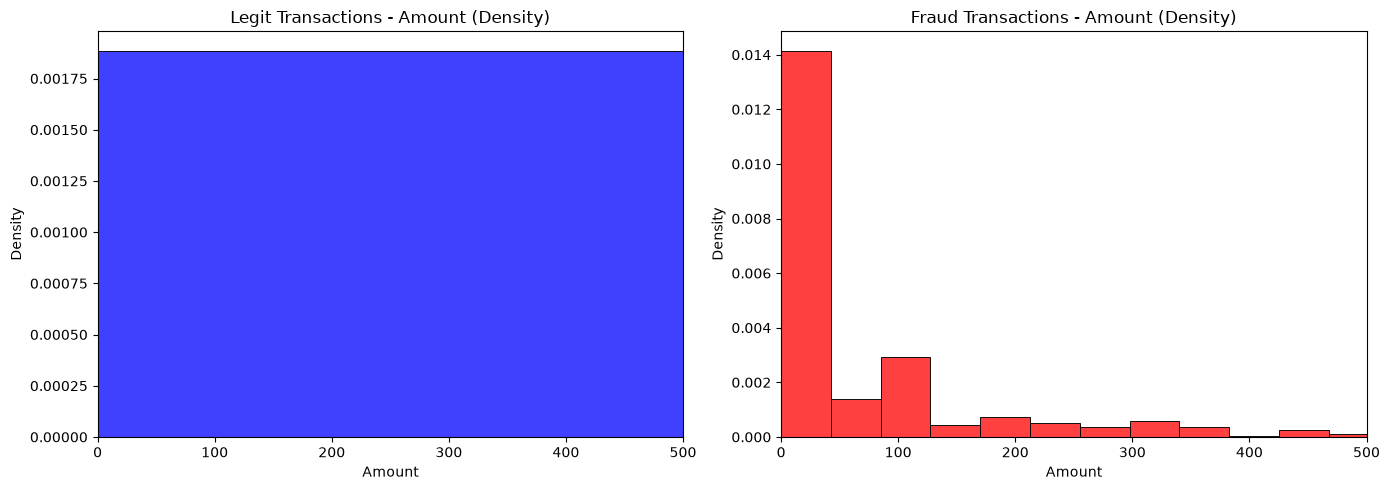

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[df['Class']==0]['Amount'], bins=50, ax=axes[0], color='blue', stat='density')
axes[0].set_title('Legit Transactions - Amount (Density)')
axes[0].set_xlim(0, 500)

sns.histplot(df[df['Class']==1]['Amount'], bins=50, ax=axes[1], color='red', stat='density')
axes[1].set_title('Fraud Transactions - Amount (Density)')
axes[1].set_xlim(0, 500)

plt.tight_layout()
plt.show()

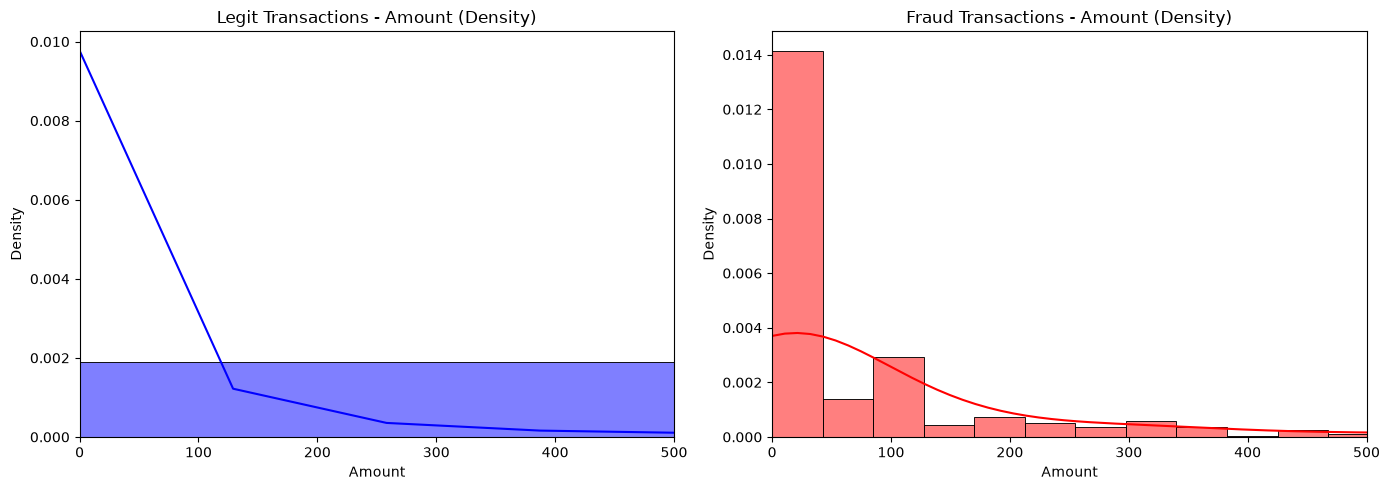

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[df['Class']==0]['Amount'], bins=50, ax=axes[0], color='blue', stat='density', kde=True)
axes[0].set_title('Legit Transactions - Amount (Density)')
axes[0].set_xlim(0, 500)

sns.histplot(df[df['Class']==1]['Amount'], bins=50, ax=axes[1], color='red', stat='density', kde=True)
axes[1].set_title('Fraud Transactions - Amount (Density)')
axes[1].set_xlim(0, 500)

plt.tight_layout()
plt.show()

In [14]:

df['Hour'] = (df['Time'] // 3600) % 24

print(df[['Time', 'Hour']].head())


   Time  Hour
0   0.0   0.0
1   0.0   0.0
2   1.0   0.0
3   1.0   0.0
4   2.0   0.0


In [15]:
print(df.groupby('Class')['Hour'].value_counts(normalize=True).sort_index())

Class  Hour
0      0.0     0.027044
       1.0     0.014808
       2.0     0.011505
       3.0     0.012222
       4.0     0.007689
       5.0     0.010478
       6.0     0.014392
       7.0     0.025394
       8.0     0.036111
       9.0     0.055650
       10.0    0.058351
       11.0    0.059100
       12.0    0.054176
       13.0    0.053982
       14.0    0.058200
       15.0    0.057806
       16.0    0.057792
       17.0    0.056757
       18.0    0.059814
       19.0    0.054974
       20.0    0.058871
       21.0    0.062209
       22.0    0.054278
       23.0    0.038398
1      0.0     0.012195
       1.0     0.020325
       2.0     0.115854
       3.0     0.034553
       4.0     0.046748
       5.0     0.022358
       6.0     0.018293
       7.0     0.046748
       8.0     0.018293
       9.0     0.032520
       10.0    0.016260
       11.0    0.107724
       12.0    0.034553
       13.0    0.034553
       14.0    0.046748
       15.0    0.052846
       16.0    0.044715
    

In [16]:
fraud_rate_by_hour = df.groupby('Hour')['Class'].mean() * 100
print(fraud_rate_by_hour.sort_values(ascending=False))

Hour
2.0     1.712740
4.0     1.041195
3.0     0.486827
5.0     0.367893
7.0     0.317548
11.0    0.314428
1.0     0.236967
6.0     0.219459
18.0    0.193673
23.0    0.191991
17.0    0.179389
15.0    0.157949
14.0    0.138805
16.0    0.133714
19.0    0.121414
13.0    0.110641
12.0    0.110246
20.0    0.107424
9.0     0.101023
21.0    0.090380
8.0     0.087583
0.0     0.077973
22.0    0.058286
10.0    0.048199
Name: Class, dtype: float64


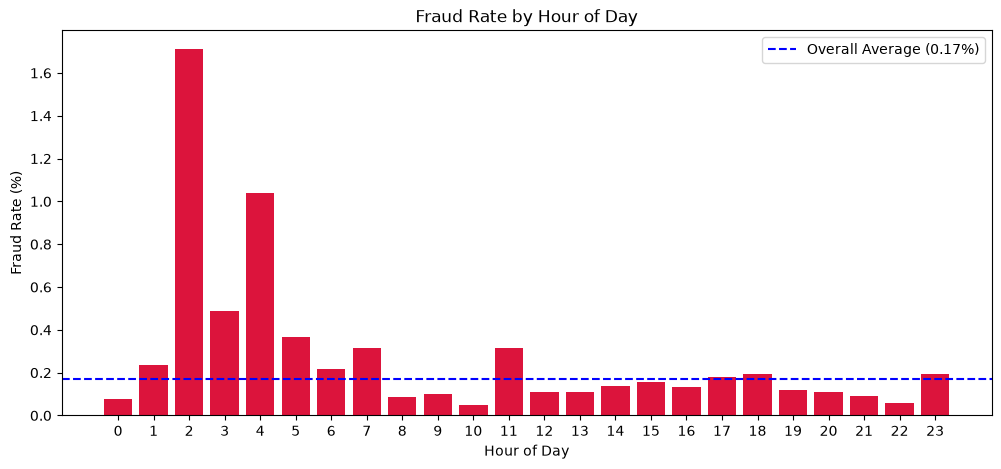

In [17]:
import matplotlib.pyplot as plt

fraud_rate_by_hour = df.groupby('Hour')['Class'].mean() * 100

plt.figure(figsize=(12, 5))
plt.bar(fraud_rate_by_hour.index, fraud_rate_by_hour.values, color='crimson')
plt.axhline(y=0.1727, color='blue', linestyle='--', label='Overall Average (0.17%)')
plt.xlabel('Hour of Day')
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate by Hour of Day')
plt.xticks(range(0,24))
plt.legend()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)   
y = df['Class']                 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)
print("Training set fraud %:", y_train.mean() * 100)
print("Testing set fraud %:", y_test.mean() * 100)

Training set fraud %: 0.17292457591783889
Testing set fraud %: 0.17204452090867595


In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model.fit(X_train, y_train)

C:\Users\jyoti\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [20]:
y_pred = model.predict(X_test)

In [21]:
print(y_pred[:20])

[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)         

In [23]:
model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [24]:
print("Model trained successfully!")
print(y_pred[:20])

Model trained successfully!
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [25]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[55363  1501]
 [    9    89]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.91      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.94      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [26]:
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
print(y_pred_proba[:10])

[6.61383841e-03 6.85425607e-02 5.23448297e-06 9.76363853e-03
 9.35403750e-01 9.72466737e-03 4.84436387e-04 1.06317693e-02
 6.56872099e-02 3.71151103e-03]


In [27]:
import numpy as np

y_pred_new = (y_pred_proba >= 0.9).astype(int)

from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred_new))
print(classification_report(y_test, y_pred_new))

[[56524   340]
 [   11    87]]
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.20      0.89      0.33        98

    accuracy                           0.99     56962
   macro avg       0.60      0.94      0.66     56962
weighted avg       1.00      0.99      1.00     56962



In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)   # Note: Random Forest ko scaling ki zaroorat NAHI hoती

y_pred_rf = rf_model.predict(X_test)

from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[56857     7]
 [   19    79]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.81      0.86        98

    accuracy                           1.00     56962
   macro avg       0.96      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [29]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.head(10))

   Feature  Importance
14     V14    0.196596
10     V10    0.145055
4       V4    0.097137
12     V12    0.095044
11     V11    0.069888
17     V17    0.065643
3       V3    0.048940
7       V7    0.032693
16     V16    0.029074
2       V2    0.022317


In [30]:
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

In [31]:
# 1. Class Distribution
class_dist = df['Class'].value_counts().reset_index()
class_dist.columns = ['Class', 'Count']
class_dist['Class'] = class_dist['Class'].map({0: 'Legit', 1: 'Fraud'})
class_dist.to_csv('../data/processed/class_distribution.csv', index=False)

# 2. Fraud Rate by Hour
fraud_by_hour = (df.groupby('Hour')['Class'].mean() * 100).reset_index()
fraud_by_hour.columns = ['Hour', 'Fraud_Rate_Percent']
fraud_by_hour.to_csv('../data/processed/fraud_rate_by_hour.csv', index=False)

# 3. Amount Stats by Class
amount_stats = df.groupby('Class')['Amount'].agg(['mean', 'median', 'max']).reset_index()
amount_stats['Class'] = amount_stats['Class'].map({0: 'Legit', 1: 'Fraud'})
amount_stats.to_csv('../data/processed/amount_stats.csv', index=False)

# 4. Feature Importance
feature_importance.to_csv('../data/processed/feature_importance.csv', index=False)

# 5. Model Comparison
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Precision': [0.06, 0.92],
    'Recall': [0.91, 0.81],
    'F1_Score': [0.11, 0.86]
})
model_comparison.to_csv('../data/processed/model_comparison.csv', index=False)

print("All CSVs saved successfully!")

All CSVs saved successfully!
